# F1 Next-Lap Prediction - ARIMA and External Features

I will investigate now if a more complex model can perform better than the exponential smoothing and look more into the insights of the mode, making it more grey/white box and finally comparing both models and choosing the one for the final application.

To make this comparison plausible and correct, I will make the pipeline the same way as the other model, same splits, inputs and data used, but I will add more features to the model.

## Imports and Loading Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

laps = pd.read_pickle("../data/prepared_race_laps_2022_2025.pkl")

display(
    laps.groupby("Season").agg(
        Races=("RoundNumber", "nunique"),
        LapRecords=("LapNumber", "size"),
        EligiblePairs=("EligiblePair", "sum")
    )
)

print(f"Total eligible pairs: {laps['EligiblePair'].sum():,}")
laps_eligible = laps.loc[laps["EligiblePair"]].copy()

,Races,LapRecords,EligiblePairs
Season,,,
2022,22,23577,16971
2023,22,24420,18902
2024,24,26604,21394
2025,24,26689,20969


Total eligible pairs: 78,236


## Data Split

In [2]:
training_history = laps[laps["Season"] < 2024].copy()
validation_history = laps[laps["Season"] == 2024].copy()
testing_history = laps[laps["Season"] == 2025].copy()

## Preparing uninterrupted lap sequences

I keep laps that are totally clean, in the race-pace, so the sequence will always start over, every time there is an interruption on the race.

In [3]:
keys = ["Season", "RoundNumber", "DriverNumber"]


def prepare_sequences(history):

    usable = (
        history["LapTimeSeconds"].notna()
        & history["IsPitLap"].eq(False)
        & history["TrackStatus"].eq("1")
        & history["IsAccurate"].eq(True)
    )

    sequences = (
        history.loc[usable]
        .sort_values(keys + ["LapNumber"])
        .copy()
    )

    sequences["Segment"] = (
        sequences.groupby(keys)["LapNumber"]
        .diff().ne(1).cumsum()
    )

    sequences["HistoryLaps"] = (
        sequences.groupby("Segment").cumcount() + 1
    )

    return sequences


training_sequences = prepare_sequences(training_history)
validation_sequences = prepare_sequences(validation_history)
testing_sequences = prepare_sequences(testing_history)

print("Usable training laps:", len(training_sequences))
print("Training sequences:", training_sequences["Segment"].nunique())

sequence_lengths = training_sequences.groupby("Segment").size()
display(sequence_lengths.describe().round(1))

prediction_rows = training_sequences.loc[
    training_sequences["EligiblePair"]
].copy()

coverage = pd.DataFrame({
    "MinimumHistory": [5, 10, 15, 20]
})

coverage["PairsWithEnoughHistory"] = [
    prediction_rows["HistoryLaps"].ge(minimum).sum()
    for minimum in coverage["MinimumHistory"]
]

coverage["CoveragePercent"] = (
    100 * coverage["PairsWithEnoughHistory"] / len(prediction_rows)
)

display(coverage.round(1))

Usable training laps: 39312
Training sequences: 3439


count    3439.0
mean       11.4
std         8.7
min         1.0
25%         4.0
50%        10.0
75%        16.0
max        53.0
dtype: float64

,MinimumHistory,PairsWithEnoughHistory,CoveragePercent
0,5,24524,68.4
1,10,14386,40.1
2,15,7488,20.9
3,20,3601,10.0


My training data has 39.312 usable laps across 3.439 uninterrupted sequences. The average in these sequences are 11.4 laps, the median is 10 and the largest sequence contains 53 laps

Only 40.1% have at least ten observations avaliable in this sequence.

While starting the ARIMA model I will need to look into how these affects the model and maybe create fallback systems to make sure the model can understand this smaller patterns

## First ARIMA Model

I begin with a basic ARIMA model using only previous lap times.
External features will be investigated later.

For this first example, I select the longest training sequence and use
its first ten observations to predict the next lap. The actual next-lap
time is used only to evaluate the prediction.

I will compare results with the same-lap baseline and the notebook from 05_timeseriesforecasting

In [4]:
example_segment=sequence_lengths.idxmax()

example = training_sequences.loc[
    training_sequences["Segment"] == example_segment
].sort_values("LapNumber").copy()

display(
    example[["Season", "EventName", "Driver"]].drop_duplicates()
)

history = example["LapTimeSeconds"].iloc[:10].to_numpy()

model=ARIMA(history, order=(1,1,0), trend="n")
fitted=model.fit()

prediction=fitted.forecast(steps=1)[0]
baseline=history[-1]
actual=example["LapTimeSeconds"].iloc[10]

comparison = pd.DataFrame({
    "Model": ["ARIMA", "Same-lap baseline"],
    "Prediction": [prediction, baseline],
    "Actual": [actual, actual],
})

comparison["AbsoluteError"] = (
    comparison["Actual"] - comparison["Prediction"]
).abs()

display(comparison.round(3))

,Season,EventName,Driver
27886,2023,Miami Grand Prix,SAR


,Model,Prediction,Actual,AbsoluteError
0,ARIMA,93.754,93.937,0.183
1,Same-lap baseline,93.681,93.937,0.256


Based on this one prediction, ARIMA got a better value than the same-lap baseline. Now I will look into more detail on different laps and then on the splits to have a final conclusion

## Forecasting

In [5]:
forecasts=[]

for i in range(10,len(example)):
    history=example["LapTimeSeconds"].iloc[:i].to_numpy()

    fitted=ARIMA(history, order=(1,1,0), trend="n").fit()
    prediction=fitted.forecast(steps=1)[0]

    smoothing = (
        pd.Series(history)
        .ewm(alpha=0.9, adjust=False)
        .mean()
        .iloc[-1]
    )

    forecasts.append({
        "LapNumber": example["LapNumber"].iloc[i],
        "Actual": example["LapTimeSeconds"].iloc[i],
        "ARIMA": prediction,
        "Baseline": history[-1],
        "Smoothing": smoothing,
    })

example_forecasts = pd.DataFrame(forecasts)

absolute_errors = (
    example_forecasts[["Baseline", "Smoothing", "ARIMA"]]
    .sub(example_forecasts["Actual"], axis=0)
    .abs()
)

example_forecasts["BestModel"] = absolute_errors.idxmin(axis=1)

display(example_forecasts.head(10).round(3))

,LapNumber,Actual,ARIMA,Baseline,Smoothing,BestModel
0,14.0,93.937,93.754,93.681,93.693,ARIMA
1,15.0,94.223,93.791,93.937,93.913,Baseline
2,16.0,93.748,94.102,94.223,94.192,ARIMA
3,17.0,93.506,94.002,93.748,93.792,Baseline
4,18.0,93.521,93.583,93.506,93.535,Smoothing
5,19.0,93.607,93.516,93.521,93.522,Smoothing
6,20.0,93.574,93.581,93.607,93.599,ARIMA
7,21.0,93.553,93.584,93.574,93.576,Baseline
8,22.0,93.384,93.559,93.553,93.555,Baseline
9,23.0,93.501,93.436,93.384,93.401,ARIMA


Across the 43 evaluated laps, ARIMA had the lowest MAE at 0.3395 seconds, followed by smoothing at 0.3497 and the baseline at 0.3651. ARIMA was also the closest model on 21 laps. These results favour ARIMA for this sequence, but they must be checked across other drivers and races.

In [6]:
closest_counts = (
    example_forecasts["BestModel"]
    .value_counts()
    .reindex(absolute_errors.columns, fill_value=0)
)

example_summary = pd.DataFrame({
    "MAE": absolute_errors.mean(),
    "RMSE": np.sqrt((absolute_errors ** 2).mean()),
    "ClosestLaps": closest_counts,
})

print("Evaluated predictions:", len(example_forecasts))
display(example_summary.sort_values("MAE").round(4))

Evaluated predictions: 43


,MAE,RMSE,ClosestLaps
ARIMA,0.3395,0.5279,21
Smoothing,0.3497,0.5477,8
Baseline,0.3651,0.5695,14


Across these 43 laps, the ARIMA model had a better performance in MAE and RMSE and predicted better 21/43 laps, so this model in this example is already having a better performance than the baseline and the Holt's expontential smoothing model.
Of course, this is for only one race, one driver and a certain sequence, so conclusions can only be taken in the validation and testing splits.

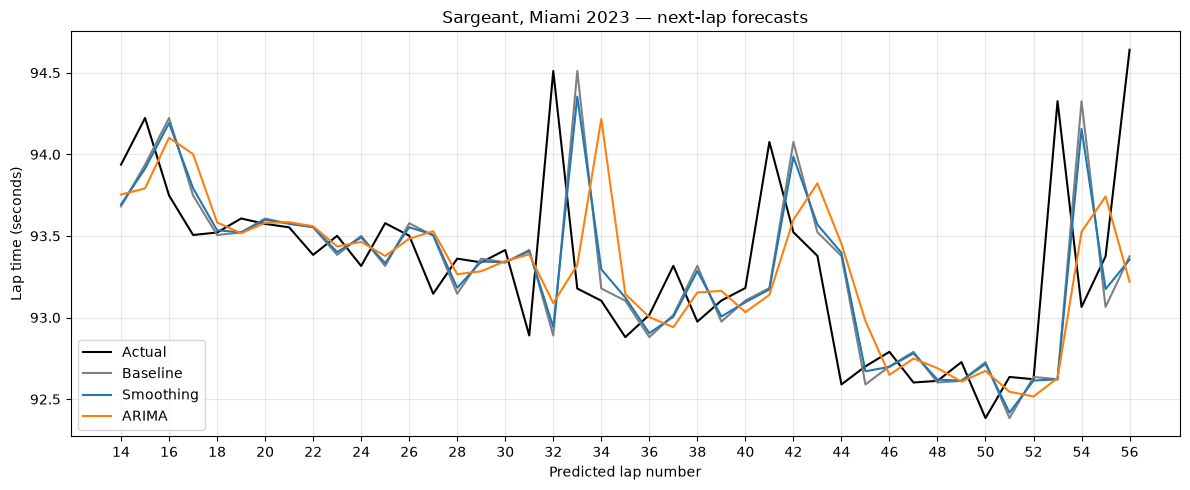

In [7]:
example_forecasts.plot(
    x="LapNumber",
    y=["Actual", "Baseline", "Smoothing", "ARIMA"],
    color=["black", "gray", "tab:blue", "tab:orange"],
    figsize=(12, 5)
)

plt.xlabel("Predicted lap number")
plt.ylabel("Lap time (seconds)")
plt.title("Sargeant, Miami 2023 — next-lap forecasts")
plt.grid(alpha=0.3)
plt.xticks(range(14,57,2))
plt.tight_layout()
plt.show()

The forecasts generally followed the lap-time evolution, but all methods struggled with sudden changes. The baseline repeats the previous lap time, while smoothing behaves similarly because it gives high weight to the latest observation.

ARIMA sometimes predicted a reversal successfully, but also made incorrect corrections. This plot does not identify the causes of the sudden changes.

## Fallback system of the model

In [4]:
def forecast_arima(history, min_history=10):

    baseline = history[-1]

    if len(history) < min_history:
        return baseline, "Baseline: short history"

    try:
        fitted = ARIMA(history, order=(1, 1, 0), trend="n").fit()
        prediction = fitted.forecast(steps=1)[0]

        if fitted.mle_retvals.get("converged", False) and np.isfinite(prediction):
            return prediction, "ARIMA"

    except (ValueError, np.linalg.LinAlgError):
        return baseline, "Baseline: fit failed"

    return baseline, "Baseline: unreliable fit"

## Forecasting in the Training Split

In [9]:
training_forecasts = training_sequences.copy()

training_forecasts["Baseline"] = training_forecasts["LapTimeSeconds"]
training_forecasts["ARIMA"] = np.nan
training_forecasts["Smoothing"] = np.nan
training_forecasts["Method"] = ""

segments = training_sequences.groupby("Segment")

for number, (_, sequence) in enumerate(segments, start=1):

    times = sequence["LapTimeSeconds"].to_numpy()
    training_forecasts.loc[sequence.index, "Smoothing"] = (
        sequence["LapTimeSeconds"]
        .ewm(alpha=0.9, adjust=False)
        .mean()
    )

    for i, row_index in enumerate(sequence.index):

        history = times[:i + 1]

        prediction, method = forecast_arima(history)

        training_forecasts.loc[row_index, "ARIMA"] = prediction
        training_forecasts.loc[row_index, "Method"] = method

    if number % 500 == 0:
        print(f"Processed {number} / {segments.ngroups} sequences")

training_errors = training_forecasts.loc[
    training_forecasts["EligiblePair"]
].copy()

print("Evaluated training pairs:", len(training_errors))
display(training_errors["Method"].value_counts())

c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = supe

Processed 500 / 3439 sequences


c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.star

Processed 1000 / 3439 sequences


c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters fou

Processed 1500 / 3439 sequences


... (5 outputs left out)

Processed 3000 / 3439 sequences


c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = supe

Evaluated training pairs: 35873


Method
Baseline: short history     21487
ARIMA                       14289
Baseline: unreliable fit       97
Name: count, dtype: int64

## Training Evaluation

In [10]:
evaluation = training_errors.loc[
    training_errors["Method"] == "ARIMA"
].copy()

actual = evaluation["NextLapTimeSeconds"]
scores = []

for name in ["Baseline", "Smoothing", "ARIMA"]:

    predictions = evaluation[name]

    scores.append({
        "Model": name,
        "MAE": mean_absolute_error(actual, predictions),
        "RMSE": np.sqrt(mean_squared_error(actual, predictions)),
        "R2": r2_score(actual, predictions),
    })

training_comparison = pd.DataFrame(scores).sort_values("MAE")

coverage = 100 * len(evaluation) / len(training_errors)

print("Evaluated pairs:", len(evaluation))
print(f"Coverage: {coverage:.1f}%")

display(training_comparison.round(4))

Evaluated pairs: 14289
Coverage: 39.8%


,Model,MAE,RMSE,R2
1,Smoothing,0.3668,0.6774,0.9960
0,Baseline,0.3758,0.6876,0.9958
2,ARIMA,0.3852,0.6907,0.9958


On the evaluated training laps, smoothing achieved the lowest MAE, followed by the baseline and ARIMA. The initial ARIMA configuration did not improve forecasting accuracy. This comparison includes only successful ARIMA predictions, covering 39.8% of eligible training pairs.

## Forecasting Validation and Evaluation

In [11]:
validation_forecasts = validation_sequences.copy()

validation_forecasts["Baseline"] = validation_forecasts["LapTimeSeconds"]
validation_forecasts["ARIMA"] = np.nan
validation_forecasts["Smoothing"] = np.nan
validation_forecasts["Method"] = ""

segments = validation_sequences.groupby("Segment")

for number, (_, sequence) in enumerate(segments, start=1):

    times = sequence["LapTimeSeconds"].to_numpy()

    validation_forecasts.loc[sequence.index, "Smoothing"] = (
        sequence["LapTimeSeconds"]
        .ewm(alpha=0.9, adjust=False)
        .mean()
    )

    for i, row_index in enumerate(sequence.index):

        history = times[:i + 1]

        prediction, method = forecast_arima(history)

        validation_forecasts.loc[row_index, "ARIMA"] = prediction
        validation_forecasts.loc[row_index, "Method"] = method

    if number % 500 == 0:
        print(f"Processed {number} / {segments.ngroups} sequences")

validation_errors = validation_forecasts.loc[
    validation_forecasts["EligiblePair"]
].copy()

print("Evaluated validation pairs:", len(validation_errors))
display(validation_errors["Method"].value_counts())


validation_evaluation = validation_errors.loc[
    validation_errors["Method"] == "ARIMA"
].copy()

actual = validation_evaluation["NextLapTimeSeconds"]
scores = []

for name in ["Baseline", "Smoothing", "ARIMA"]:

    predictions = validation_evaluation[name]

    scores.append({
        "Model": name,
        "MAE": mean_absolute_error(actual, predictions),
        "RMSE": np.sqrt(mean_squared_error(actual, predictions)),
        "R2": r2_score(actual, predictions),
    })

validation_comparison = pd.DataFrame(scores).sort_values("MAE")

validation_coverage = (
    100 * len(validation_evaluation) / len(validation_errors)
)

print("Evaluated pairs with ARIMA:", len(validation_evaluation))
print(f"Coverage: {validation_coverage:.1f}%")

display(validation_comparison.round(4))

c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = supe

Processed 500 / 1605 sequences


c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary start

Processed 1000 / 1605 sequences


c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = supe

Processed 1500 / 1605 sequences


c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Francisco\Deskt

Evaluated validation pairs: 21394


Method
Baseline: short history     10939
ARIMA                       10406
Baseline: unreliable fit       49
Name: count, dtype: int64

Evaluated pairs with ARIMA: 10406
Coverage: 48.6%


,Model,MAE,RMSE,R2
1,Smoothing,0.4355,0.8561,0.9922
0,Baseline,0.4447,0.8752,0.9919
2,ARIMA,0.4614,0.9637,0.9901


## Validation Errors

In [12]:
history_analysis = validation_evaluation.copy()

history_analysis["HistoryGroup"] = pd.cut(
    history_analysis["HistoryLaps"],
    bins=[9, 14, 19, 29, np.inf],
    labels=["10-14", "15-19", "20-29", "30+"]
)
for name in ["Baseline", "Smoothing", "ARIMA"]:
    history_analysis[f"{name}Error"] = (
        history_analysis[name]
        - history_analysis["NextLapTimeSeconds"]
    ).abs()

history_comparison = (
    history_analysis.groupby("HistoryGroup", observed=True)
    .agg(
        Predictions=("ARIMAError", "size"),
        BaselineMAE=("BaselineError", "mean"),
        SmoothingMAE=("SmoothingError", "mean"),
        ARIMAMAE=("ARIMAError", "mean")
    )
)

history_comparison["ARIMA_vs_Smoothing"] = (
    history_comparison["ARIMAMAE"]
    - history_comparison["SmoothingMAE"]
)

display(history_comparison.round(4))

,Predictions,BaselineMAE,SmoothingMAE,ARIMAMAE,ARIMA_vs_Smoothing
HistoryGroup,,,,,
10-14,4021,0.3836,0.3748,0.3933,0.0185
15-19,2784,0.4788,0.4690,0.5301,0.0611
20-29,2535,0.4654,0.4588,0.4665,0.0077
30+,1066,0.5369,0.5211,0.5270,0.0059


ARIMAl in the validation split, has worse MAE results compared to all models, but after having more than 30 laps it performs better than the baseline

## ARIMA Hyperparameter Tuning
Since, the results I got in the validation split, were quite underwhelming, I am now looking more into detail of the model to improve it. I will start by using Optuna to find out the best possible combinations for the model.

In [13]:
import optuna

tuning_rows = validation_sequences.loc[
    validation_sequences["EligiblePair"]
    & validation_sequences["HistoryLaps"].ge(10)
].sample(n=100, random_state=42)

tuning_cases = []

for _, row in tuning_rows.iterrows():
    history = validation_sequences.loc[
        validation_sequences["Segment"].eq(row["Segment"])
        & validation_sequences["LapNumber"].le(row["LapNumber"]),
        "LapTimeSeconds"
    ].to_numpy()

    tuning_cases.append((history, row["NextLapTimeSeconds"]))

actual_values = pd.Series([
    actual for history, actual in tuning_cases
])

trial_predictions = {}


def objective(trial):

    p = trial.suggest_int("p", 0, 1)
    d = trial.suggest_int("d", 0, 1)
    q = trial.suggest_int("q", 0, 1)

    linear_trend = trial.suggest_categorical(
        "linear_trend", [False, True]
    )

    if d == 0:
        trend = "ct" if linear_trend else "c"
    else:
        trend = "t" if linear_trend else "n"

    trial.set_user_attr("trend", trend)
    predictions = np.full(len(tuning_cases), np.nan)

    for i, (history, actual) in enumerate(tuning_cases):

        try:
            fitted = ARIMA(
                history,
                order=(p, d, q),
                trend=trend
            ).fit()

            prediction = fitted.forecast(steps=1)[0]

        except (ValueError, np.linalg.LinAlgError):
            continue

        if (
            not fitted.mle_retvals.get("converged", False)
            or not np.isfinite(prediction)
        ):
            continue

        predictions[i] = prediction

    trial_predictions[trial.number] = predictions
    successful = np.isfinite(predictions)

    if not successful.any():
        return float("inf")

    return mean_absolute_error(
        actual_values[successful],
        predictions[successful]
    )


search_space = {
    "p": [0, 1],
    "d": [0, 1],
    "q": [0, 1],
    "linear_trend": [False, True]
}

study = optuna.create_study(
    direction="minimize",
    sampler=optuna.samplers.GridSampler(search_space, seed=42)
)

study.optimize(objective, n_trials=16)

tuning_results = study.trials_dataframe()

predictions = pd.DataFrame(trial_predictions)
common_cases = predictions.notna().all(axis=1)

errors = predictions.loc[common_cases].sub(
    actual_values.loc[common_cases], axis=0
).abs()

tuning_results["MAE"] = tuning_results["number"].map(
    errors.mean()
)

tuning_results["CoveragePercent"] = tuning_results["number"].map(
    predictions.notna().mean() * 100
)

print(
    "Shared successful cases:",
    common_cases.sum(),
    "/",
    len(tuning_cases)
)

display(
    tuning_results[
        [
            "params_p",
            "params_d",
            "params_q",
            "user_attrs_trend",
            "MAE",
            "CoveragePercent"
        ]
    ].sort_values("MAE").round(4)
)

c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[I 2026-10-22 21:58:19,420] A new study created in memory with name: no-name-7b680c5f-ee78-4354-af8c-3ddd6cb75824
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
[I 2026-10-22 21:58:23,206] Trial 0 finished with value: 0.6009847381095527 and parameters: {'p': 0, 'd': 0

Shared successful cases: 62 / 100


,params_p,params_d,params_q,user_attrs_trend,MAE,CoveragePercent
14,1,0,1,c,0.4214,96.0
12,1,1,0,n,0.4248,99.0
7,0,1,1,n,0.4324,100.0
3,1,1,0,t,0.4338,100.0
8,1,0,0,c,0.4373,100.0
4,0,1,1,t,0.4455,100.0
6,0,1,0,n,0.4479,99.0
5,1,1,1,n,0.4582,99.0
13,0,1,0,t,0.4669,99.0
15,1,0,0,ct,0.4992,97.0


In [16]:
best = tuning_results.sort_values("MAE").iloc[0]

actual = actual_values.loc[common_cases]

baseline_predictions = pd.Series([
    history[-1]
    for history, actual in tuning_cases
]).loc[common_cases]

smoothing_predictions = pd.Series([
    pd.Series(history).ewm(alpha=0.9, adjust=False).mean().iloc[-1]
    for history, actual in tuning_cases
]).loc[common_cases]

sample_comparison = pd.DataFrame({
    "Model": ["Baseline", "Smoothing", "Tuned ARIMA"],
    "MAE": [
        mean_absolute_error(actual, baseline_predictions),
        mean_absolute_error(actual, smoothing_predictions),
        best["MAE"]
    ]
}).sort_values("MAE")

print(
    "Selected configuration:",
    (int(best["params_p"]), int(best["params_d"]), int(best["params_q"]))
)
print("Trend:", best["user_attrs_trend"])
print("Compared cases:", common_cases.sum())

display(sample_comparison.round(4))

Selected configuration: (1, 0, 1)
Trend: c
Compared cases: 62


,Model,MAE
2,Tuned ARIMA,0.4214
1,Smoothing,0.4341
0,Baseline,0.4479


On the 62 validation cases observed, a tuned ARIMA model performed better, achieving a lower MAE than the  Holt's Exponential Smoothing by ~0.1 seconds. This setup will be validated one last time, before being testes for the final version of this project.

## Tuned Validation Split

In [17]:
tuned_validation = validation_forecasts.loc[
    validation_forecasts["EligiblePair"]
].copy()

tuned_validation["TunedARIMA"] = np.nan

segments = validation_sequences.groupby("Segment")

for number, (_, sequence) in enumerate(segments, start=1):
    times = sequence["LapTimeSeconds"].to_numpy()

    for i in range(9, len(times)):
        if not sequence["EligiblePair"].iloc[i]:
            continue

        try:
            fitted = ARIMA(times[:i + 1], order=(1, 0, 1), trend="c").fit()
            prediction = fitted.forecast(steps=1)[0]

            if fitted.mle_retvals.get("converged", False) and np.isfinite(prediction):
                tuned_validation.at[sequence.index[i], "TunedARIMA"] = prediction

        except (ValueError, np.linalg.LinAlgError):
            continue

    if number % 200 == 0:
        print(f"Processed {number} / {segments.ngroups} sequences")

tuned_evaluation = tuned_validation.loc[
    tuned_validation["Method"].eq("ARIMA")
    & tuned_validation["TunedARIMA"].notna()
]

actual = tuned_evaluation["NextLapTimeSeconds"]
scores = []

for name in ["Baseline", "Smoothing", "ARIMA", "TunedARIMA"]:
    predictions = tuned_evaluation[name]

    scores.append({
        "Model": name,
        "MAE": mean_absolute_error(actual, predictions),
        "RMSE": np.sqrt(mean_squared_error(actual, predictions)),
        "R2": r2_score(actual, predictions)
    })

tuned_validation_comparison = pd.DataFrame(scores).sort_values("MAE")

print(f"Tuned ARIMA coverage: {100 * tuned_validation['TunedARIMA'].notna().mean():.1f}%")
print("Compared pairs:", len(tuned_evaluation))
print(f"Shared coverage: {100 * len(tuned_evaluation) / len(tuned_validation):.1f}%")

display(tuned_validation_comparison.round(4))

c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters fou

Processed 200 / 1605 sequences


c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_re

Processed 400 / 1605 sequences


c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found.

Processed 600 / 1605 sequences


... (9 outputs left out)

Processed 1600 / 1605 sequences


c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible start

Tuned ARIMA coverage: 46.4%
Compared pairs: 9882
Shared coverage: 46.2%


,Model,MAE,RMSE,R2
1,Smoothing,0.4419,0.8693,0.9920
0,Baseline,0.4512,0.8888,0.9916
2,ARIMA,0.4688,0.9810,0.9898
3,TunedARIMA,0.4869,0.9088,0.9912


## Saving Models

Running the whole notebook takes quite a long time and I need to save the models and re-use them to avoid repeating this process all the time.

In [18]:
pd.to_pickle({
    "training_forecasts": training_forecasts,
    "validation_forecasts": validation_forecasts,
    "tuned_validation": tuned_validation,
    "tuning_results": tuning_results,
    "trial_predictions": trial_predictions,
    "tuning_cases": tuning_cases
}, "../data/arima_results.pkl")

print("Results saved.")

Results saved.


In [5]:
saved = pd.read_pickle("../data/arima_results.pkl")

training_forecasts = saved["training_forecasts"]
validation_forecasts = saved["validation_forecasts"]
tuned_validation = saved["tuned_validation"]
tuning_results = saved["tuning_results"]
trial_predictions = saved["trial_predictions"]
tuning_cases = saved["tuning_cases"]

actual_values = pd.Series([
    actual for history, actual in tuning_cases
])

common_cases = pd.DataFrame(trial_predictions).notna().all(axis=1)

print("Results loaded.")

Results loaded.


## Final Test Evaluation

In [6]:
testing_forecasts = testing_sequences.copy()

testing_forecasts["Baseline"] = testing_forecasts["LapTimeSeconds"]
testing_forecasts["Smoothing"] = np.nan
testing_forecasts["ARIMA"] = np.nan
testing_forecasts["Method"] = ""

segments = testing_sequences.groupby("Segment")

for number, (_, sequence) in enumerate(segments, start=1):
    times = sequence["LapTimeSeconds"].to_numpy()

    testing_forecasts.loc[sequence.index, "Smoothing"] = (
        sequence["LapTimeSeconds"].ewm(alpha=0.9, adjust=False).mean()
    )

    for i, row_index in enumerate(sequence.index):
        if not sequence["EligiblePair"].iloc[i]:
            continue

        prediction, method = forecast_arima(times[:i + 1])

        testing_forecasts.at[row_index, "ARIMA"] = prediction
        testing_forecasts.at[row_index, "Method"] = method

    if number % 200 == 0:
        print(f"Processed {number} / {segments.ngroups} sequences")

testing_forecasts.to_pickle("../data/arima_test_forecasts.pkl")

testing_errors = testing_forecasts.loc[
    testing_forecasts["EligiblePair"]
].copy()

testing_evaluation = testing_errors.loc[
    testing_errors["Method"].eq("ARIMA")
].copy()

actual = testing_evaluation["NextLapTimeSeconds"]
scores = []

for name in ["Baseline", "Smoothing", "ARIMA"]:
    predictions = testing_evaluation[name]

    scores.append({
        "Model": name,
        "MAE": mean_absolute_error(actual, predictions),
        "RMSE": np.sqrt(mean_squared_error(actual, predictions)),
        "R2": r2_score(actual, predictions)
    })

testing_comparison = pd.DataFrame(scores).sort_values("MAE")

print("Eligible test pairs:", len(testing_errors))
print("Compared pairs:", len(testing_evaluation))
print(f"ARIMA coverage: {100 * len(testing_evaluation) / len(testing_errors):.1f}%")

display(testing_errors["Method"].value_counts())
display(testing_comparison.round(4))

c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.star

Processed 200 / 1540 sequences


c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Francisco\Deskt

Processed 400 / 1540 sequences


c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.star

Processed 600 / 1540 sequences


... (8 outputs left out)

c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = supe

Eligible test pairs: 20969
Compared pairs: 10502
ARIMA coverage: 50.1%


Method
ARIMA                       10502
Baseline: short history     10401
Baseline: unreliable fit       66
Name: count, dtype: int64

,Model,MAE,RMSE,R2
1,Smoothing,0.3467,0.6607,0.9953
0,Baseline,0.3549,0.6830,0.9950
2,ARIMA,0.3670,0.7452,0.9941


## Final Conclusions

On the 2025 test set, exponential smoothing achieved the lowest MAE
(0.3467 seconds), followed by the baseline (0.3549) and ARIMA (0.3670).
ARIMA also had the highest RMSE, indicating greater sensitivity to
large prediction errors.

The advantage observed in the initial Sargeant example did not
generalise to the broader evaluation. Hyperparameter tuning produced
a promising result on a small validation sample, but this improvement
was not maintained on the full validation set.

ARIMA produced valid forecasts for 50.1% of eligible test pairs.
Insufficient history was the main reason for using the fallback.
All reported model comparisons exclude fallback predictions and
use the same successful ARIMA cases.

For the evaluated forecasting task, exponential smoothing remains
the preferred method. These findings apply to the tested ARIMA
configurations and do not establish that all ARIMA models are inferior.